In [1]:
import pandas as pd, numpy as np, glob
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme()
path = glob.glob("../data/*.csv")[0]
print("Fișier:", path)
df = pd.read_csv(path)
df.shape

Fișier: ../data\Goodreadss Books.csv


(20068, 24)

Verificarea tipurilor de date si a coloanelor

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20068 entries, 0 to 20067
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          20068 non-null  int64  
 1   bookId              20068 non-null  int64  
 2   title               19509 non-null  str    
 3   author              19507 non-null  str    
 4   series              4279 non-null   str    
 5   description         17381 non-null  str    
 6   genres              19812 non-null  str    
 7   awards              3129 non-null   str    
 8   characters          4779 non-null   str    
 9   places              4040 non-null   str    
 10  isbn                17531 non-null  str    
 11  isbn13              19210 non-null  str    
 12  language            17289 non-null  str    
 13  first_publish_date  14591 non-null  str    
 14  publish_date        19022 non-null  str    
 15  num_pages           18428 non-null  float64
 16  num_ratings    

Curatarea primara a datelor (eliminarea spatiilor albe)

In [3]:
df.columns = df.columns.str.strip().str.replace(r'\s+', ' ', regex=True)

print("Numele coloanelor din dataset:")
print(df.columns.tolist())
print("-" * 40)

print("--- Valori Lipsă (Null) ---")
print(df.isnull().sum())

Numele coloanelor din dataset:
['Unnamed: 0', 'bookId', 'title', 'author', 'series', 'description', 'genres', 'awards', 'characters', 'places', 'isbn', 'isbn13', 'language', 'first_publish_date', 'publish_date', 'num_pages', 'num_ratings', 'num_reviews', 'avg_rating', 'rated_1', 'rated_2', 'rated_3', 'rated_4', 'rated_5']
----------------------------------------
--- Valori Lipsă (Null) ---
Unnamed: 0                0
bookId                    0
title                   559
author                  561
series                15789
description            2687
genres                  256
awards                16939
characters            15289
places                16028
isbn                   2537
isbn13                  858
language               2779
first_publish_date     5477
publish_date           1046
num_pages              1640
num_ratings             559
num_reviews             559
avg_rating              559
rated_1                3430
rated_2                3430
rated_3            

Observatii!!! 
Exista un numar mic de carti fara titlu sau autor. Vor trebui eliminate sau completate cu un text generic, ca Unknown. Trebuie tratate atent si descrierile lipsa si genurile literare lipsa.


Voi elimina Unnamed: 0

In [25]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

Verific duplicatele dupa tiltu si autor

In [26]:
print("Duplicate după titlu și autor:", df.duplicated(subset=['title', 'author']).sum())

Duplicate după titlu și autor: 1941


In [32]:
# sortam dupa rating ca sa patram ce e mai relevant
df = df.sort_values(by='num_ratings', ascending=False)

# eliminam pastrand prima aparitie, cea mai populara
df = df.drop_duplicates(subset=['title', 'author'], keep='first')

print(f"Număr de cărți rămase după eliminarea duplicatelor: {len(df)}")

Număr de cărți rămase după eliminarea duplicatelor: 18127


Vizualizez distributia ratingului mediu

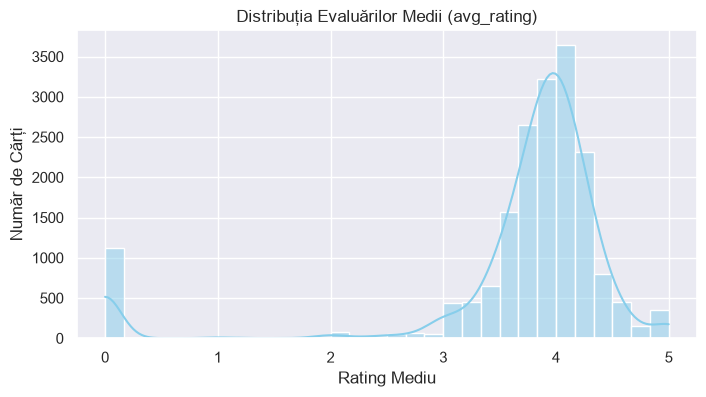

In [33]:
plt.figure(figsize=(8, 4))
sns.histplot(df['avg_rating'].dropna(), bins=30, kde=True, color='skyblue')
plt.title('Distribuția Evaluărilor Medii (avg_rating)')
plt.xlabel('Rating Mediu')
plt.ylabel('Număr de Cărți')
plt.show()

un top al primilor 10 autori

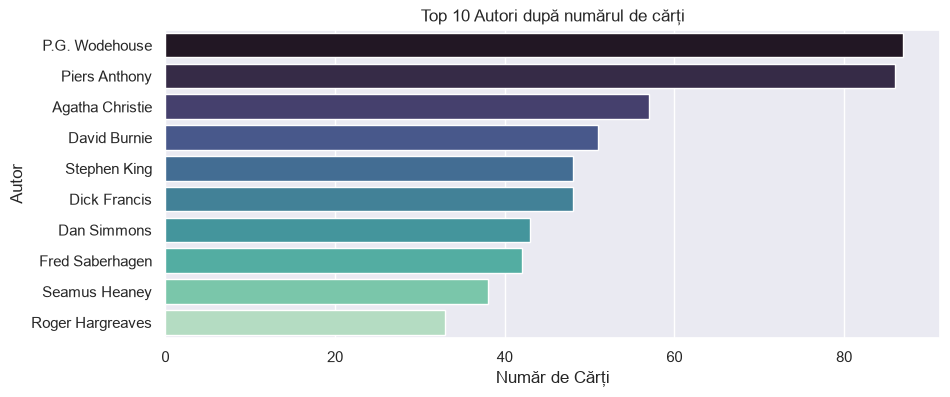

In [34]:
top_authors = df['author'].value_counts().head(10)

plt.figure(figsize=(10, 4))
sns.barplot(
    x=top_authors.values, 
    y=top_authors.index, 
    hue=top_authors.index, 
    palette='mako', 
    legend=False
)
plt.title('Top 10 Autori după numărul de cărți')
plt.xlabel('Număr de Cărți')
plt.ylabel('Autor')
plt.show()

Analiza lungimii textului din descriere (pentru TF-IDF)

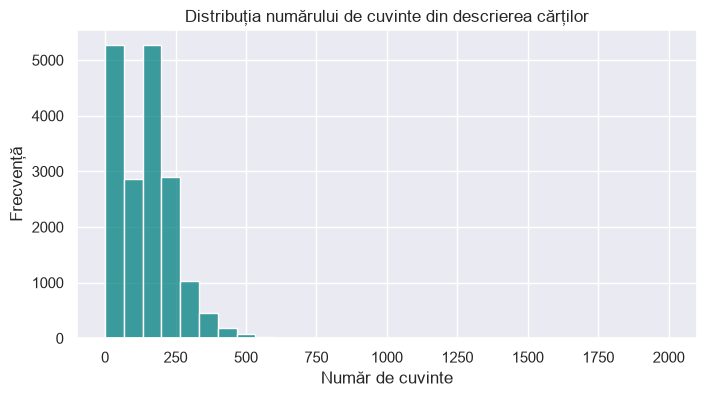

In [35]:
df['desc_len'] = df['description'].fillna('').apply(lambda x: len(x.split()))
plt.figure(figsize=(8, 4))
sns.histplot(df['desc_len'], bins=30, color='teal')
plt.title('Distribuția numărului de cuvinte din descrierea cărților')
plt.xlabel('Număr de cuvinte')
plt.ylabel('Frecvență')
plt.show()

Extragerea si numararea genurilor literare

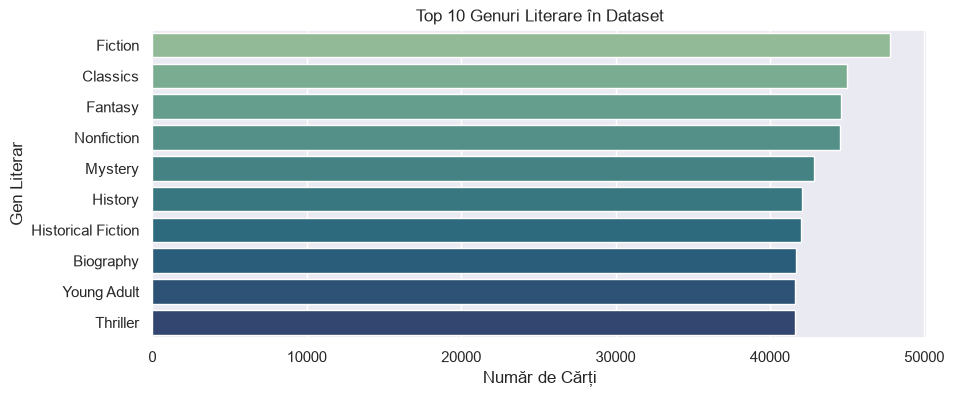

In [4]:
top_genres = df['genres'].dropna().str.split(',').explode().str.strip().value_counts().head(10)

plt.figure(figsize=(10, 4))
sns.barplot(
    x=top_genres.values, 
    y=top_genres.index, 
    hue=top_genres.index, 
    palette='crest', 
    legend=False
)
plt.title('Top 10 Genuri Literare în Dataset')
plt.xlabel('Număr de Cărți')
plt.ylabel('Gen Literar')
plt.show()

Distributia limbilor in care sunt scrise

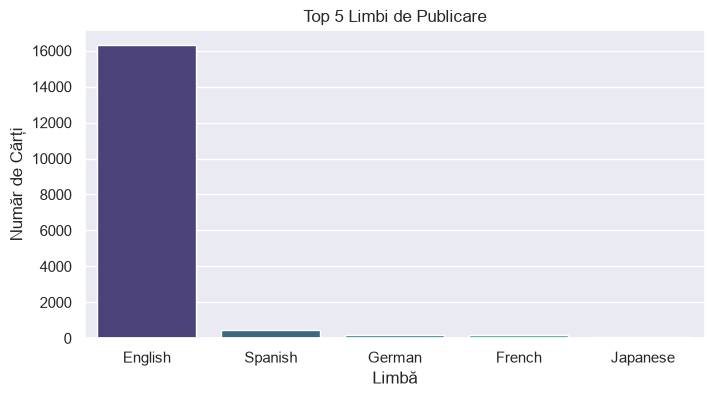

In [5]:
top_languages = df['language'].value_counts().head(5)

plt.figure(figsize=(8, 4))
sns.barplot(
    x=top_languages.index, 
    y=top_languages.values, 
    hue=top_languages.index, 
    palette='viridis', 
    legend=False
)
plt.title('Top 5 Limbi de Publicare')
plt.xlabel('Limbă')
plt.ylabel('Număr de Cărți')
plt.show()